# Supervised pixel classification with machine learning

*Section 4 — Image classification, notebook 3 of 5.* Previous: `02_unsupervised_classification`. Next: `04_object_based_classification`.

**You will learn:**
- how to define classes and their training polygons in a `ClassificationConfig`;
- how to extract training pixels and split them into balanced training, validation and testing sets;
- how to optimise, train and apply a scikit-learn random forest classifier to an image;
- how to map the result beside the image, with a legend, using `create_map_panels`.

**Before you start:** notebooks `01_rule_based_classification` (class names, colours and thematic maps) and `02_unsupervised_classification` (`ImageBandInfo`). Reading vector layers with GeoPandas was covered in `02_making_maps` and `03_vector_data_and_zonal_stats`.

**Data:** `../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif` (Sentinel-2, 20 m), its valid-pixel mask `../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_vmsk.tif` and the training polygons `../data/cls_data/aber_sen2_cls_training.gpkg` (one layer per class).

**Run time:** about 2 minutes.

## Introduction

Image classification is one of the most common data analysis steps undertaken with remotely sensed data. A wide variety of approaches can be adopted, but machine learning-based approaches, maybe combined with simple rule bases, are probably the most commonly used in the current literature.

rsgispy has classification modules (`rsgispy.classification`) which allow both pixel and segment (object) based classifications using various machine learning algorithms and libraries.

In this tutorial, we will go through the critical steps in performing a per-pixel machine learning classification using the [scikit-learn](https://scikit-learn.org) library, which has many different classification algorithms implemented, as well as regression algorithms (see section 5).

The steps included in this tutorial are:

 * Defining sample data
 * Extracting sample data
 * Balancing sample data and creating training, validation and testing subsets
 * Training the classifier
 * Applying the classifier

When undertaking a classification, it is recommended to consider why the classes of interest are separable. Can a visible difference between the classes be seen in a particular band combination, or is there a strong seasonal change in response which allows the classes to be separated? From your knowledge of the classes, are there other variables which might help separate the classes? For example, some classes might only be found above or below a specific elevation or close to water; therefore, this information could be provided to the classifier (as the indices were in notebook 1).

## Running the notebook

The notebook has been run and saved with its outputs, so you can see what the outputs should look like and browse it online without running it.

If you run the notebook yourself, it is a good idea to clear the stored outputs first: in JupyterLab use *Edit > Clear Outputs of All Cells*, or in the classic Notebook *Cell > All Output > Clear*.

# 1. Import modules

In [1]:
# Import modules from python standard library
import os

# Import Geopandas for vector analysis (https://geopandas.org)
import geopandas
import pandas

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline
import matplotlib.pyplot as plt

# Import the rsgispy modules for the notebook
import rsgispy.classification.classsklearn as csk
import rsgispy.mapping.layout as map_layout
from rsgispy.classification.classdata import (
    ClassificationConfig,
    ClassInfoObj,
    ImageBandInfo,
    extract_class_training_samples,
    split_class_samples,
    write_cls_config,
)
from rsgispy.imageutils.metadata import get_band_names, get_img_bbox
from rsgispy.mapping.legend import add_categorical_legend, save_categorical_legend_img
from rsgispy.mapping.raster import create_thematic_raster_map
from rsgispy.vector.io import get_vec_lyrs_lst

# scikit-learn imports
from sklearn.ensemble import RandomForestClassifier

## 1.1 Define the input image files

The input image files are defined, along with the directory for the outputs:

In [2]:
# Input Sentinel-2 image file with 20 m resolution pixels.
input_img = "../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif"

# A valid pixel mask for the input image - this is required for later
# steps but note that for this particular image all the pixel values
# are valid (i.e., there are no 'no data' regions).
in_msk_img = "../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_vmsk.tif"

# All the outputs of this notebook are written to this directory.
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

# 2. Defining training samples

Samples are defined using polygon or point vector layers. Each layer represents a class, and within that layer, multiple polygons/points are used to identify pixels belonging to the class of interest. Note the vector layer needs to be in the same projection as the input image(s).

Samples are defined by either referencing an existing dataset or manually digitising regions using a desktop GIS. [QGIS](https://www.qgis.org) is the freely available and easiest to access desktop GIS which can be used for this purpose, but other desktop GIS packages (e.g., ArcGIS) are also available.

Remember, when defining your reference dataset, you want to ensure you get a similar number of pixels sampled for all classes. This might be problematic for classes which are limited in geographic coverage. However, you also want to ensure you get good geographic coverage and don't have a small number of large polygons that are all geographically clustered - this can result in an overestimation of your classifier accuracy due to overfitting caused by spatial autocorrelation.

For this analysis, the following GeoPackage (GPKG) file has a set of layers defining the training data. Open the layers in a GIS and examine them before proceeding with the tutorial. After you have run through the tutorial you might consider revising this reference data, rerunning the classification and seeing what difference it makes.

In [3]:
vec_train_file = "../data/cls_data/aber_sen2_cls_training.gpkg"

## 2.1 List the vector layers

To find out which layers are within the vector file, and therefore the classes training data has been provided for:

In [4]:
# Get the list of layers within the vector file.
lyr_names = get_vec_lyrs_lst(vec_train_file)

# Print out the layer names by looping through the list of layers returned.
# Note. the enumerate function returns the list index and the list value:
for i, lyr_name in enumerate(lyr_names):
    print(f"{i+1}:\t{lyr_name}")

1:	Artificial_Surfaces
2:	Bare_Rock_Sand
3:	Conifer_Forest
4:	Deciduous_Forest
5:	Grass_Long
6:	Grass_Short
7:	NonPhotosynthetic_Vegetation
8:	Scrub
9:	Water_Training
10:	Bracken


## 2.2 Define the classes

For each class we define the output pixel value (class ID) in the classified image, the layer with its training polygons, and a colour. It is useful to define colours manually, as it makes it much easier for the end user to interpret the map. Colours are defined as Red, Green and Blue (RGB) values between 0-255 (or as hexadecimal strings, `"#RRGGBB"`). There are many tools to look up colours online (try searching 'Colour picker'). The class names and IDs are the same as in notebook 1.

In [5]:
# class name: (output pixel value, vector layer, (red, green, blue))
classes = {
    "Artificial_Surfaces": (1, "Artificial_Surfaces", (180, 180, 180)),
    "Bare_Rock_Sand": (2, "Bare_Rock_Sand", (131, 250, 252)),
    "Conifer_Forest": (3, "Conifer_Forest", (0, 105, 16)),
    "Deciduous_Forest": (4, "Deciduous_Forest", (62, 168, 78)),
    "Grass_Long": (5, "Grass_Long", (247, 176, 32)),
    "Grass_Short": (6, "Grass_Short", (252, 231, 109)),
    "NonPhoto_Veg": (7, "NonPhotosynthetic_Vegetation", (156, 255, 215)),
    "Scrub": (8, "Scrub", (225, 114, 247)),
    "Water": (9, "Water_Training", (0, 0, 255)),
    "Bracken": (10, "Bracken", (140, 255, 0)),
}

## 2.3 Visualise the training data

It is recommended that you open the input image (`sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif`) and training samples (`aber_sen2_cls_training.gpkg`) in QGIS (or equivalent) to see the regions which have been defined for training, as this allows you to pan and zoom around the data.

However, an overview visualisation is shown below for illustration: the image, and the training polygons drawn over the image with each layer in its class colour. `create_map_panels` draws the two maps side by side with the same extent; the second is a `'vector'` panel, with the image as its `base_img`, and the extra options for drawing the vector layers in `map_kw`. If you change the bounding box you can pan and zoom around the scene. Note the training samples are quite small compared to the whole scene and therefore can be hard to see.

In [6]:
# Get the full image bounding box (xmin, xmax, ymin, ymax).
img_bbox = get_img_bbox(input_img)
print(img_bbox)

BBox(west=249177.3321426216, east=315077.3321426216, south=268742.255157026, north=326342.255157026, epsg=27700)


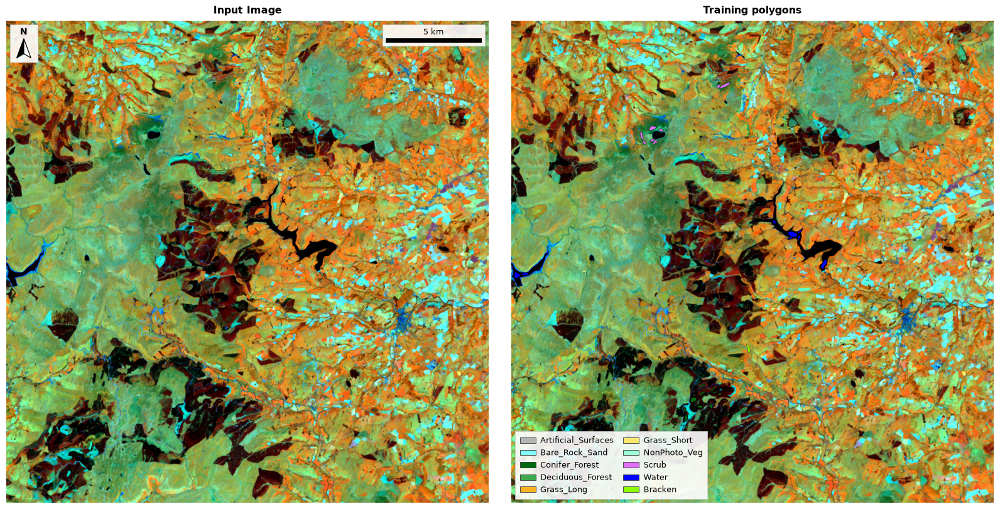

In [7]:
# Define a bbox for the subset to be displayed
sub_img_bbox = [275000, 300000, 275000, 300000]

gp_vecs = list()
lyr_clrs = list()
for cls_name, (cls_id, lyr_name, clr) in classes.items():
    # Read the samples to a geopandas dataframe
    gp_vecs.append(geopandas.read_file(vec_train_file, layer=lyr_name))
    # Matplotlib colours are (red, green, blue) values between 0 and 1.
    lyr_clrs.append(tuple(c / 255 for c in clr))

fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel(
            "vector",
            vec=gp_vecs,
            base_img=input_img,
            base_bands=[8, 9, 3],
            map_kw={"vec_fill_clrs": lyr_clrs, "vec_line_clrs": "black"},
            title="Training polygons",
        ),
    ],
    bbox=sub_img_bbox,
    figsize=(16, 8),
)
# The legend only covers thematic panels, so the class legend is added to
# the vector panel.
_ = add_categorical_legend(
    axs[1], classes_info={i: (n, c) for n, (i, l, c) in classes.items()}, loc="lower left"
)

# 3. Extract training samples

For the analysis, the values of the individual pixels within the training polygons are extracted from the image and stored in a table (a pandas `DataFrame`, which can be saved as a [Parquet](https://parquet.apache.org) file). Tables from several images or dates can be merged with pandas.

## 3.1 Define images and bands for classification

Before the image pixel values can be extracted or the classification performed, the relevant images and bands within those images need to be defined. Clearly, these need to be defined identically for extracting the image samples and for the classification step. If they are not, the trained classifier will not work as intended, which is likely to produce very poor classification results.

To define the images and bands, a list of `ImageBandInfo` objects is used (as in the previous notebook). The band names given here become the column names of the sample tables and the feature names of the classifier.

In [8]:
img_band_info = list()
img_band_info.append(
    ImageBandInfo(
        input_img,
        name="sen2",
        bands=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
        band_names=get_band_names(input_img),
    )
)

## 3.2 Define the classes and the vector samples

Each class is defined with a `ClassInfoObj` object (output class ID, vector file, vector layer and colour). The images/bands and the classes are then put together in a `ClassificationConfig` object, which is used by all the following steps. It can be saved to a JSON file so the same set-up can be reused (e.g., to apply the classifier later).

> Note. the `out_id` will be the output pixel value for the class in the output image.

> **RSGISLib users:** this replaces `ClassVecSamplesInfoObj`, `get_class_training_data` and the per-class HDF5 files; the samples are in one table with a class column.

In [9]:
class_info = dict()
for cls_name, (cls_id, lyr_name, clr) in classes.items():
    class_info[cls_name] = ClassInfoObj(
        out_id=cls_id, vec_file=vec_train_file, vec_lyr=lyr_name, colour=clr
    )

cls_cfg = ClassificationConfig(img_band_info, class_info)

# Save the configuration to a JSON file.
cls_cfg_file = os.path.join(out_dir, "cls_config.json")
write_cls_config(cls_cfg_file, cls_cfg)

print(cls_cfg.get_band_names())
print(cls_cfg.get_class_names_lut())

['Blue', 'Green', 'Red', 'RE_B5', 'RE_B6', 'RE_B7', 'NIR_B8', 'NIR_B8A', 'SWIR1', 'SWIR2']
{1: 'Artificial_Surfaces', 2: 'Bare_Rock_Sand', 3: 'Conifer_Forest', 4: 'Deciduous_Forest', 5: 'Grass_Long', 6: 'Grass_Short', 7: 'NonPhoto_Veg', 8: 'Scrub', 9: 'Water', 10: 'Bracken'}


## 3.3 Perform sample extraction

The `extract_class_training_samples` function extracts the pixel values within the polygons of each class. The vector layers are rasterised to the pixel grid of the image internally, so no temporary directory is needed. The `poly_id_col` option records which polygon each pixel came from (we will come back to this in section 3.5).

In [10]:
all_smpls_file = os.path.join(out_dir, "cls_smpls_all.parquet")
smpls_df = extract_class_training_samples(
    cls_cfg, out_file=all_smpls_file, poly_id_col="train_grp", use_pbar=False
)
smpls_df.head()

,class_name,out_cls_id,internal_cls_id,train_grp,Blue,Green,Red,RE_B5,RE_B6,RE_B7,NIR_B8,NIR_B8A,SWIR1,SWIR2
0,Artificial_Surfaces,1,0,Artificial_Surfaces:poly0,91,101,111,141,191,202,167,215,206,162
1,Artificial_Surfaces,1,0,Artificial_Surfaces:poly0,90,99,107,142,202,215,177,228,211,164
2,Artificial_Surfaces,1,0,Artificial_Surfaces:poly1,127,138,140,156,203,217,236,213,176,141
3,Artificial_Surfaces,1,0,Artificial_Surfaces:poly1,146,149,158,165,194,196,211,205,175,149
4,Artificial_Surfaces,1,0,Artificial_Surfaces:poly1,172,177,185,175,199,194,211,199,192,171


## 3.4 How many training samples were extracted

The samples are in one table, so counting the samples of each class is a pandas `value_counts`:

In [11]:
smpls_df["class_name"].value_counts()

class_name
Water                  34232
Scrub                   6059
Bare_Rock_Sand          5437
Deciduous_Forest        4054
Conifer_Forest          3335
NonPhoto_Veg            1999
Bracken                 1403
Grass_Long              1264
Grass_Short              622
Artificial_Surfaces      454
Name: count, dtype: int64

Observing the number of samples which are available for the classes there are a number of things which could be done. First, the samples should be balanced (i.e., the same number per class), and this would require using the class with the minimum number of samples as the reference for defining the number of training, validation and testing samples. Alternatively, the sample data can be oversampled, or there are algorithms which attempt to generate artificial training samples (e.g., the [imbalanced-learn](https://imbalanced-learn.org) library).

For this tutorial, things will be kept simple and the class (Artificial_Surfaces) with the lowest number of samples will be used to define the number of samples for each class:

 * Training: 350
 * Validation: 50
 * Testing: 50

 The samples are randomly selected from the population of input samples.

## 3.5 Balance and extract training / validation and testing datasets

The `split_class_samples` function splits the samples of each class into the three sets, with the number of samples per class given by `n_train`, `n_valid` and `n_test`. Each set is saved as a Parquet file.

> **Spatial autocorrelation:** here the pixels are split at random, so the pixels of one training polygon usually end up in all three sets. Neighbouring pixels are very similar, so the testing accuracy will be optimistic. With `group_col="train_grp"` the split instead keeps all the pixels of a polygon in one set, which gives a more honest accuracy estimate (but needs enough polygons per class). Try it once you have run through the notebook.

In [12]:
smpls_dir = os.path.join(out_dir, "cls_smpls")
os.makedirs(smpls_dir, exist_ok=True)

train_file = os.path.join(smpls_dir, "cls_smpls_train.parquet")
valid_file = os.path.join(smpls_dir, "cls_smpls_valid.parquet")
test_file = os.path.join(smpls_dir, "cls_smpls_test.parquet")

train_df, test_df, valid_df = split_class_samples(
    smpls_df,
    n_train=350,
    n_valid=50,
    n_test=50,
    out_train_file=train_file,
    out_valid_file=valid_file,
    out_test_file=test_file,
    rnd_seed=42,
)
print(f"Training: {len(train_df)}, validation: {len(valid_df)}, testing: {len(test_df)}")

Training: 3500, validation: 500, testing: 500


You now have three Parquet files (look within the `outputs/cls_smpls` directory) with the pixels extracted from the scene for training, validating and testing the classifier.

To see what is within one of these files, read it with pandas. There are 50 samples per class, each with the class name, the output (`out_cls_id`) and internal (`internal_cls_id`, numbered from 0 as scikit-learn expects) class IDs, the polygon they came from and the 10 values of the Sentinel-2 bands we specified.

In [13]:
valid_smpls_df = pandas.read_parquet(valid_file)
print(valid_smpls_df.shape)
valid_smpls_df.groupby("class_name")[cls_cfg.get_band_names()].mean().round(1)

(500, 14)


,Blue,Green,Red,RE_B5,RE_B6,RE_B7,NIR_B8,NIR_B8A,SWIR1,SWIR2
class_name,,,,,,,,,,
Artificial_Surfaces,157.5,171.8,187.1,207.2,237.2,241.5,245.1,250.1,258.4,227.8
Bare_Rock_Sand,95.1,118.4,134.4,153.2,169.6,172.0,171.0,175.0,175.3,150.6
Bracken,34.7,76.7,31.5,141.9,585.1,683.2,719.0,737.9,274.0,115.8
Conifer_Forest,26.0,44.8,20.3,75.3,258.9,304.0,315.5,322.7,98.0,39.2
Deciduous_Forest,27.5,48.2,22.5,91.7,390.9,481.9,506.4,526.6,206.0,84.6
Grass_Long,36.0,66.7,32.5,120.3,466.0,608.9,638.4,660.2,219.6,99.3
Grass_Short,58.6,89.9,89.0,175.3,336.9,391.5,430.1,461.4,396.7,231.5
NonPhoto_Veg,76.8,109.6,153.6,223.1,305.3,346.5,387.1,422.1,453.7,292.7
Scrub,36.3,53.2,51.4,115.1,235.2,264.6,284.1,302.2,249.9,131.5


# 4. Train the classifier

## 4.1 Optimise classifier parameters

Machine learning algorithms have many parameters, which can alter the way the classifier runs or the way it represents the feature space. These parameters can significantly alter the classification result. It is therefore important that we optimise the parameters of the classifier to best suit the problem being solved.

The first step is to define the search space, i.e., the parameters to be searched and what values to try for those parameters.

In this case we will run a grid search to find the optimal parameters, which tries all the combinations of the parameters specified, scoring each with 5-fold cross-validation on the training samples. For large training datasets the optimisation can take some time to run, so subsets can be used or alternative search algorithms such as random search or Bayesian optimisation (`search_method="random"` or `"optuna"`).

In [14]:
sk_classifier = csk.perform_sklearn_classifier_param_search(
    cls_cfg,
    RandomForestClassifier(random_state=42),
    train_file,
    param_space={
        "n_estimators": [10, 20, 50, 100, 150, 200],
        "max_depth": [4, 8, 10, 12, 14, 16],
    },
    search_method="grid",
    cv=5,
    n_jobs=-1,  # use all the CPU cores
    rnd_seed=42,
    use_pbar=False,
)
print(sk_classifier)

RandomForestClassifier(max_depth=16, random_state=42)


## 4.2 Train optimised classifier

Now we have the optimised classifier parameters we can train on the full training dataset. The trained classifier is saved to a file, and its accuracy is calculated for the training, validation and testing samples (the overall accuracy, balanced accuracy, macro F1 score and Cohen's kappa).

In [15]:
model_file = os.path.join(out_dir, "rf_classifier.joblib")
metrics = csk.train_sklearn_classifier(
    cls_cfg,
    sk_classifier,
    train_file,
    test_data=test_file,
    valid_data=valid_file,
    out_model_file=model_file,
)
pandas.Series(metrics).round(3)

train_accuracy        1.000
train_bal_accuracy    1.000
train_f1_macro        1.000
train_cohen_kappa     1.000
test_accuracy         0.986
test_bal_accuracy     0.986
test_f1_macro         0.986
test_cohen_kappa      0.984
valid_accuracy        0.984
valid_bal_accuracy    0.984
valid_f1_macro        0.984
valid_cohen_kappa     0.982
dtype: float64

The training accuracy is 1 (a random forest fits its training data almost perfectly), so it tells us little; the validation and testing accuracies are the ones to look at. They are very high, partly because the samples are random pixels from the same polygons (see section 3.5).

# 5. Apply classifier

You can now use the trained classifier to classify the input image. Note, the valid mask image that was defined at the top of the notebook is used to define which pixels are classified (those with a value of 1). As well as the classification, a score image is written with the probability of each class for each pixel.

The output is a thematic image with the class colours in its colour table.

In [16]:
out_cls_img = os.path.join(out_dir, "sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_cls.tif")
out_scr_img = os.path.join(out_dir, "sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_cls_score.tif")

csk.apply_sklearn_classifier(
    cls_cfg,
    model_file,
    in_msk_img,
    1,
    output_img=out_cls_img,
    out_score_img=out_scr_img,
    gdalformat="GTIFF",
    use_pbar=False,
)

# 6. Visualise classification results

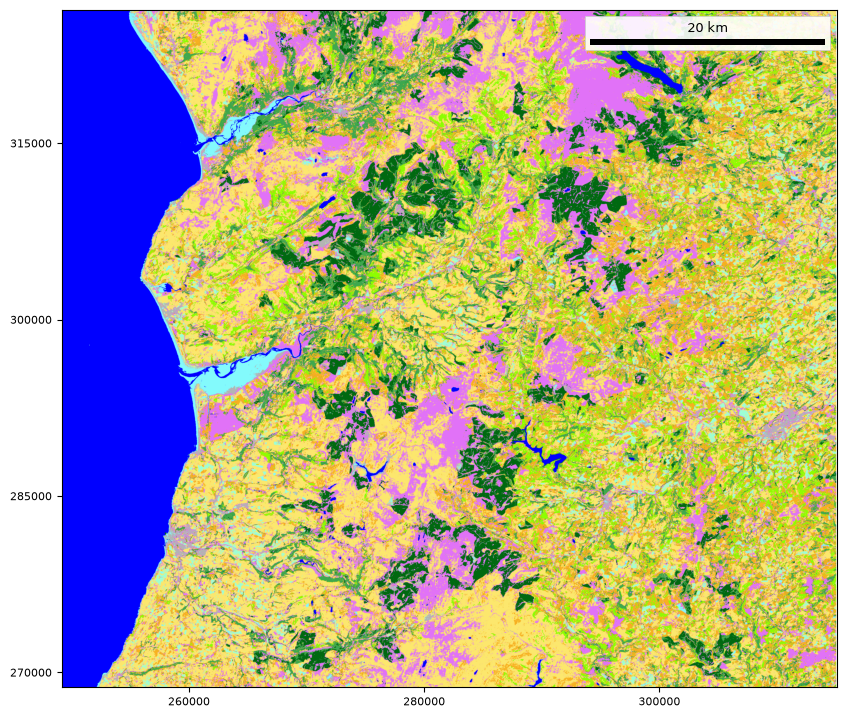

In [17]:
# Create the matplotlib figure
fig, ax = plt.subplots(figsize=(10, 10))

_ = create_thematic_raster_map(ax, out_cls_img)

## 6.1 Visualise subsets

`create_map_panels` draws the input image and the classification side by side, with the same extent. It would add a legend of the classes, but we turn that off for now (`show_legend=False`) and look at legends in the next section.

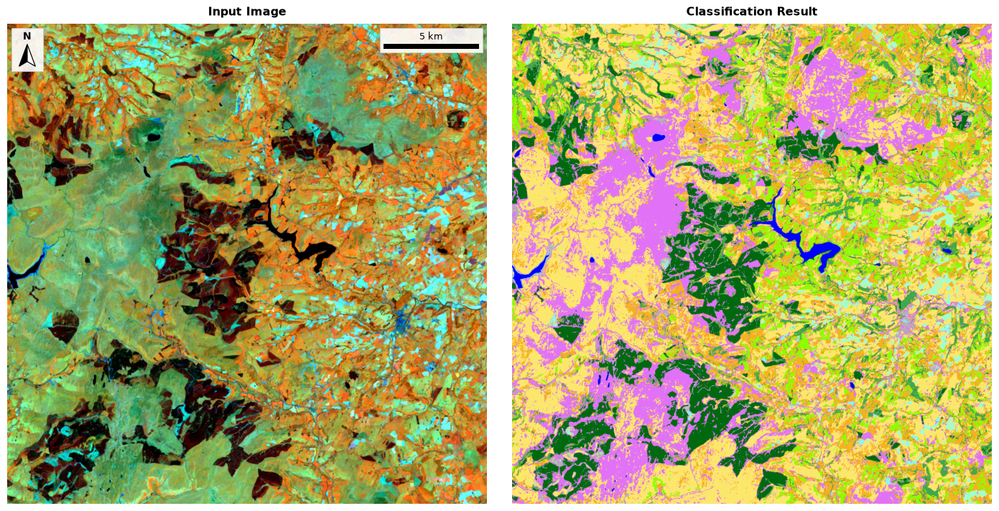

In [18]:
# Define a bbox for the subset to be displayed
sub_img_bbox = [275000, 300000, 275000, 300000]
# sub_img_bbox = [255000, 280000, 275000, 300000]
# sub_img_bbox = [295000, 300000, 295000, 300000]

fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", out_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    show_legend=False,
    figsize=(14, 7),
)

## 6.2 Create legend

It is useful, and normally required, to have a legend to go along with your map. The `rsgispy.mapping.legend` module creates legends from the class names and colours, which can be given directly by the `ClassificationConfig`. Here the legend is drawn on its own axis (`overlay=False`):

> **RSGISLib users:** this replaces `tools.plotting.create_legend_info_dict` / `create_legend_img_mpl_ax`, which read the class names from the raster attribute table.

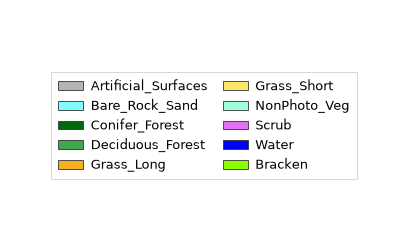

In [19]:
# Just display the legend using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
add_categorical_legend(ax, classes_info=cls_cfg, ncols=2, overlay=False)
plt.show()

In [20]:
# There is a similar function which allows the legend to be saved to an image file:
_ = save_categorical_legend_img(
    os.path.join(out_dir, "legend_img_file.png"), classes_info=cls_cfg, ncols=2
)

## 6.3 Show legend alongside map

`create_map_panels` adds one legend for its thematic panels beside the maps, listing the classes found within the extent. The class names and colours are given by the `ClassificationConfig` (`classes_info`):

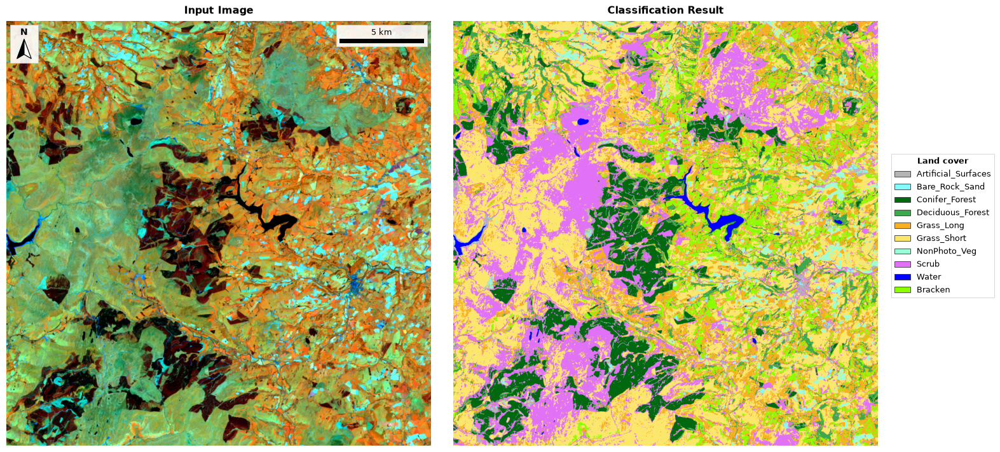

In [21]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", out_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    classes_info=cls_cfg,
    legend_title="Land cover",
    figsize=(14, 7),
)

How does this compare to the rule-based classification in notebook 1? In the next notebook we will classify segments (groups of neighbouring pixels) rather than individual pixels.